In [1]:
# import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from pandas_datareader import data as wb
from scipy import stats
import statsmodels.api as sm

In [2]:
# List of tickers
tickers = ['HBCYF', 'JPM', 'MUFG', 'ANZ.AX', '1398.HK', 'KEBNI-B.ST']
# Download 'Close' prices for all tickers at once
mydata = yf.download(tickers, start='2020-01-01', end='2026-01-01')['Close']

C:\Users\USER\AppData\Local\Temp\ipykernel_10960\3444260449.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  mydata = yf.download(tickers, start='2020-01-01', end='2026-01-01')['Close']
[*********************100%***********************]  6 of 6 completed


In [3]:
mydata.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1551 entries, 2020-01-02 to 2025-12-31
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   1398.HK     1476 non-null   float64
 1   ANZ.AX      1519 non-null   float64
 2   HBCYF       1508 non-null   float64
 3   JPM         1508 non-null   float64
 4   KEBNI-B.ST  1347 non-null   float64
 5   MUFG        1508 non-null   float64
dtypes: float64(6)
memory usage: 84.8 KB


In [4]:
mydata.head()

Ticker,1398.HK,ANZ.AX,HBCYF,JPM,KEBNI-B.ST,MUFG
Date,,,,,,
2020-01-02,3.709044,17.348942,5.536721,117.313942,NaN,5.043601
2020-01-03,3.678391,17.476145,5.602030,115.765793,NaN,5.015838
2020-01-06,3.635476,17.405476,5.485925,115.673775,NaN,5.015838
2020-01-07,3.623214,17.631617,5.413360,113.707275,NaN,4.969567
2020-01-08,3.580300,17.568012,5.377078,114.594254,NaN,4.960312


In [5]:
mydata.tail()

Ticker,1398.HK,ANZ.AX,HBCYF,JPM,KEBNI-B.ST,MUFG
Date,,,,,,
2025-12-24,5.850956,35.481052,15.378042,322.950073,NaN,15.95
2025-12-26,NaN,NaN,15.524035,321.713867,NaN,15.89
2025-12-29,5.936719,35.578800,15.193115,317.632477,1.480,15.89
2025-12-30,5.974836,35.608124,15.504570,317.308716,1.454,15.93
2025-12-31,5.946248,35.520153,15.280712,316.131409,NaN,15.86


In [6]:
mydata.iloc[0]

Ticker
1398.HK         3.709044
ANZ.AX         17.348942
HBCYF           5.536721
JPM           117.313942
KEBNI-B.ST           NaN
MUFG            5.043601
Name: 2020-01-02 00:00:00, dtype: float64

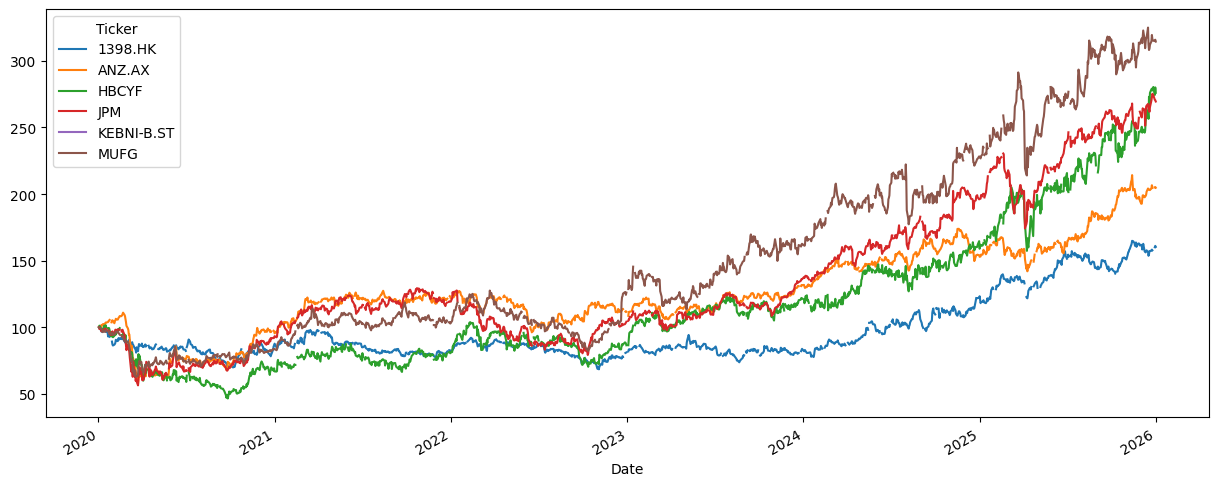

In [7]:
(mydata / mydata.iloc[0] * 100).plot(figsize = (15,6))
plt.show()

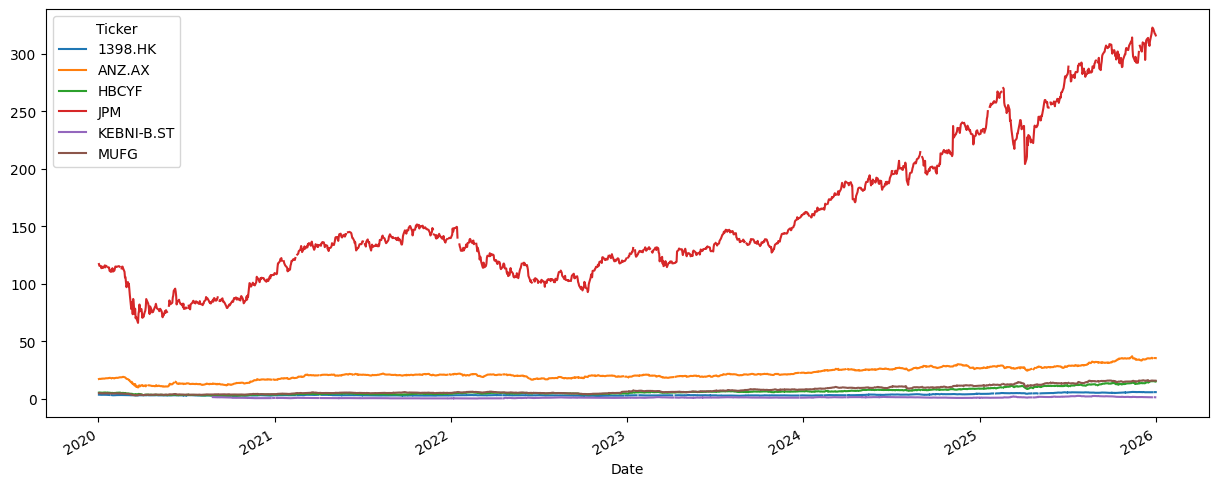

In [8]:
mydata.plot(figsize=(15,6))
plt.show()

In [9]:
# calculating the return
returns = (mydata / mydata.shift(1)) - 1
returns.head()

Ticker,1398.HK,ANZ.AX,HBCYF,JPM,KEBNI-B.ST,MUFG
Date,,,,,,
2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,-0.008264,0.007332,0.011796,-0.013197,NaN,-0.005504
2020-01-06,-0.011667,-0.004044,-0.020725,-0.000795,NaN,0.000000
2020-01-07,-0.003373,0.012993,-0.013228,-0.017000,NaN,-0.009225
2020-01-08,-0.011844,-0.003607,-0.006702,0.007801,NaN,-0.001862


In [10]:
weights = np.array([0.25, 0.25, 0.25, 0.25, 0.25, 0.25])

In [11]:
np.dot(returns, weights)

array([       nan,        nan,        nan, ...,        nan, 0.00291874,
              nan], shape=(1551,))

In [12]:
annual_returns = returns.mean() *250
annual_returns

Ticker
1398.HK       0.099871
ANZ.AX        0.139899
HBCYF         0.225753
JPM           0.225864
KEBNI-B.ST    0.180758
MUFG          0.209774
dtype: float64

In [13]:
np.dot(annual_returns, weights)

np.float64(0.27047975025822385)

In [14]:
pfolio_1 = str(round(np.dot(annual_returns, weights),5)*100) + ' %'
print(pfolio_1)

27.048 %


In [15]:
weights_2 = np.array([0.4, 0.4, 0.15, 0.05, 0.20, 0.20])

In [16]:
pfolio_2 = str(round(np.dot(annual_returns, weights_2),5)*100) +' %'
print(pfolio_2)

21.917 %


In [17]:
# return of indices
ind_returns =(mydata / mydata.shift(1))-1
ind_returns.tail()

Ticker,1398.HK,ANZ.AX,HBCYF,JPM,KEBNI-B.ST,MUFG
Date,,,,,,
2025-12-24,-0.003247,-0.010090,-0.005038,0.009941,NaN,-0.009932
2025-12-26,NaN,NaN,0.009494,-0.003828,NaN,-0.003762
2025-12-29,NaN,NaN,-0.021317,-0.012686,NaN,0.000000
2025-12-30,0.006421,0.000824,0.020500,-0.001019,-0.017568,0.002517
2025-12-31,-0.004785,-0.002471,-0.014438,-0.003710,NaN,-0.004394


In [18]:
annual_ind_returns = ind_returns.mean() * 250
annual_ind_returns

Ticker
1398.HK       0.099871
ANZ.AX        0.139899
HBCYF         0.225753
JPM           0.225864
KEBNI-B.ST    0.180758
MUFG          0.209774
dtype: float64

In [19]:
sec_returns = np.log(mydata/ mydata.shift(1))
sec_returns

Ticker,1398.HK,ANZ.AX,HBCYF,JPM,KEBNI-B.ST,MUFG
Date,,,,,,
2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,-0.008299,0.007305,0.011727,-0.013284,NaN,-0.005520
2020-01-06,-0.011735,-0.004052,-0.020943,-0.000795,NaN,0.000000
2020-01-07,-0.003378,0.012909,-0.013316,-0.017147,NaN,-0.009268
2020-01-08,-0.011915,-0.003614,-0.006725,0.007770,NaN,-0.001864
...,...,...,...,...,...,...
2025-12-24,-0.003252,-0.010141,-0.005050,0.009892,NaN,-0.009981
2025-12-26,NaN,NaN,0.009449,-0.003835,NaN,-0.003769
2025-12-29,NaN,NaN,-0.021547,-0.012768,NaN,0.000000


In [20]:
sec_returns[['1398.HK', 'ANZ.AX','HBCYF','JPM','KEBNI-B.ST','MUFG']].mean() * 250

Ticker
1398.HK       0.077918
ANZ.AX        0.107688
HBCYF         0.145904
JPM           0.176931
KEBNI-B.ST   -0.046216
MUFG          0.164777
dtype: float64

In [21]:
sec_returns[['1398.HK', 'ANZ.AX','HBCYF','JPM','KEBNI-B.ST','MUFG']].std()

Ticker
1398.HK       0.013239
ANZ.AX        0.016079
HBCYF         0.025266
JPM           0.019774
KEBNI-B.ST    0.042215
MUFG          0.018972
dtype: float64

In [22]:
sec_returns[['1398.HK', 'ANZ.AX','HBCYF','JPM','KEBNI-B.ST','MUFG']].std() * 250 ** 0.5

Ticker
1398.HK       0.209330
ANZ.AX        0.254237
HBCYF         0.399489
JPM           0.312649
KEBNI-B.ST    0.667473
MUFG          0.299979
dtype: float64

In [23]:
# calculating the covarience and correlation
HK_var = sec_returns['1398.HK'].var()
print(HK_var)
ANZ_var = sec_returns['ANZ.AX'].var()
print(ANZ_var)
HBCYF_var = sec_returns['HBCYF'].var()
print(HBCYF_var)
JPM_var = sec_returns['JPM'].var()
print(JPM_var)
KEBNI_var = sec_returns['KEBNI-B.ST'].var()
print(KEBNI_var)
MUFG_var = sec_returns['MUFG'].var()
print(MUFG_var)

0.0001752763219425583
0.0002585453369245573
0.0006383656532546147
0.0003909985612939677
0.0017820801109861483
0.00035994919080237686


In [24]:
HK_var_a = sec_returns['1398.HK'].var()*250
print(HK_var_a)
ANZ_var_a = sec_returns['ANZ.AX'].var()*250
print(ANZ_var_a)
HBCYF_var_a = sec_returns['HBCYF'].var()*250
print(HBCYF_var_a)
JPM_var_a = sec_returns['JPM'].var()*250
print(JPM_var_a)
KEBNI_var_a = sec_returns['KEBNI-B.ST'].var()*250
print(KEBNI_var_a)
MUFG_var_a = sec_returns['MUFG'].var()*250
print(MUFG_var_a)

0.04381908048563958
0.06463633423113933
0.15959141331365367
0.09774964032349193
0.4455200277465371
0.08998729770059422


In [25]:
cov_matrix = sec_returns.cov()
cov_matrix

Ticker,1398.HK,ANZ.AX,HBCYF,JPM,KEBNI-B.ST,MUFG
Ticker,,,,,,
1398.HK,0.000175,0.000049,0.000059,0.000029,0.000013,0.000044
ANZ.AX,0.000049,0.000259,0.000065,0.000108,0.000003,0.000085
HBCYF,0.000059,0.000065,0.000638,0.000179,0.000017,0.000167
JPM,0.000029,0.000108,0.000179,0.000391,-0.000016,0.000200
KEBNI-B.ST,0.000013,0.000003,0.000017,-0.000016,0.001782,0.000013
MUFG,0.000044,0.000085,0.000167,0.000200,0.000013,0.000360


In [26]:
cov_matrix = sec_returns.cov() * 250
cov_matrix

Ticker,1398.HK,ANZ.AX,HBCYF,JPM,KEBNI-B.ST,MUFG
Ticker,,,,,,
1398.HK,0.043819,0.012272,0.014630,0.007340,0.003195,0.011021
ANZ.AX,0.012272,0.064636,0.016300,0.027096,0.000786,0.021300
HBCYF,0.014630,0.016300,0.159591,0.044738,0.004271,0.041728
JPM,0.007340,0.027096,0.044738,0.097750,-0.004060,0.050069
KEBNI-B.ST,0.003195,0.000786,0.004271,-0.004060,0.445520,0.003217
MUFG,0.011021,0.021300,0.041728,0.050069,0.003217,0.089987


In [27]:
cov_matrix = sec_returns.corr()
cov_matrix

Ticker,1398.HK,ANZ.AX,HBCYF,JPM,KEBNI-B.ST,MUFG
Ticker,,,,,,
1398.HK,1.000000,0.230302,0.178309,0.112175,0.023225,0.176583
ANZ.AX,0.230302,1.000000,0.159683,0.334178,0.006293,0.273707
HBCYF,0.178309,0.159683,1.000000,0.358187,0.016986,0.348207
JPM,0.112175,0.334178,0.358187,1.000000,-0.024091,0.533848
KEBNI-B.ST,0.023225,0.006293,0.016986,-0.024091,1.000000,0.016855
MUFG,0.176583,0.273707,0.348207,0.533848,0.016855,1.000000


In [28]:
# calculating portfolio risk
weights = np.array([0.5,0.5,0.5,0.5,0.5,0.5])

In [29]:
# portfolio variance
pfolio_var = np.dot(weights.T, np.dot(sec_returns.cov() *250, weights))
pfolio_var

np.float64(0.35227795518513266)

In [30]:
# portfolio volatility
pfolio_vol = (np.dot(weights.T, np.dot(sec_returns.cov()*250, weights)))**0.5
pfolio_vol

np.float64(0.5935300794274311)

In [31]:
print (str(round(pfolio_vol, 5)*100) + '%')

59.353%


In [32]:
# Calculating Diversifiable Risk of a Portfolio
weights = np.array([0.5,0.5,0.5,0.5,0.5,0.5])

In [33]:
HK_var_a = sec_returns['1398.HK'].var()*250
print(HK_var_a)
ANZ_var_a = sec_returns['ANZ.AX'].var()*250
print(ANZ_var_a)
HBCYF_var_a = sec_returns['HBCYF'].var()*250
print(HBCYF_var_a)
JPM_var_a = sec_returns['JPM'].var()*250
print(JPM_var_a)
KEBNI_var_a = sec_returns['KEBNI-B.ST'].var()*250
print(KEBNI_var_a)
MUFG_var_a = sec_returns['MUFG'].var()*250
print(MUFG_var_a)

0.04381908048563958
0.06463633423113933
0.15959141331365367
0.09774964032349193
0.4455200277465371
0.08998729770059422


In [34]:
dr =  pfolio_var - (weights[0] **2 * HK_var_a) - (weights[1]**2 * ANZ_var_a)
dr

np.float64(0.32516410150593794)

In [35]:
print(str(round(dr*100,3))+'%')

32.516%


In [36]:
# Non- Diversifiable Risk:
n_dr_1 = pfolio_var - dr
n_dr_1

np.float64(0.02711385367919472)

In [37]:
n_dr_2 = (weights[0] **2 * HK_var_a) - (weights[1]**2 * ANZ_var_a)
n_dr_2

np.float64(-0.005204313436374938)

In [38]:
n_dr_1 == n_dr_2

np.False_

In [39]:
cov = sec_returns.cov() * 250
cov

Ticker,1398.HK,ANZ.AX,HBCYF,JPM,KEBNI-B.ST,MUFG
Ticker,,,,,,
1398.HK,0.043819,0.012272,0.014630,0.007340,0.003195,0.011021
ANZ.AX,0.012272,0.064636,0.016300,0.027096,0.000786,0.021300
HBCYF,0.014630,0.016300,0.159591,0.044738,0.004271,0.041728
JPM,0.007340,0.027096,0.044738,0.097750,-0.004060,0.050069
KEBNI-B.ST,0.003195,0.000786,0.004271,-0.004060,0.445520,0.003217
MUFG,0.011021,0.021300,0.041728,0.050069,0.003217,0.089987


In [40]:
cov_with_market = cov.iloc[0,1]
cov_with_market

np.float64(0.012271834448266612)

In [41]:
market_var1 = sec_returns['1398.HK'].var()*250
market_var1

np.float64(0.04381908048563958)

In [42]:
market_var2 = sec_returns['ANZ.AX'].var()*250
market_var2

np.float64(0.06463633423113933)

In [43]:
market_var3 = sec_returns['HBCYF'].var()*250
market_var3

np.float64(0.15959141331365367)

In [44]:
market_var4 = sec_returns['JPM'].var()*250
market_var4

np.float64(0.09774964032349193)

In [45]:
market_var5 = sec_returns['KEBNI-B.ST'].var()*250
market_var5

np.float64(0.4455200277465371)

In [46]:
market_var6 = sec_returns['MUFG'].var()*250
market_var6

np.float64(0.08998729770059422)

In [47]:
hsbc_beta = cov_with_market / market_var1
print("HSBC beta: ",hsbc_beta)
ax_beta = cov_with_market / market_var2
print("AX beta: ",ax_beta)
hbcyf_beta = cov_with_market / market_var3
print("HBCYF beta: ",hbcyf_beta)
jpm_beta = cov_with_market / market_var4
print("JPM beta: ",jpm_beta)
kebni_beta = cov_with_market / market_var5
print("ST beta: ",kebni_beta)
mufg_beta = cov_with_market / market_var6
print("MUFG beta: ",mufg_beta)

HSBC beta:  0.2800568682012473
AX beta:  0.18985969105832284
HBCYF beta:  0.07689533035306924
JPM beta:  0.1255435253536923
ST beta:  0.027544966968910855
MUFG beta:  0.1363729633164168


In [48]:
# Download data with volume information for regression analysis
tickers = ['HBCYF', 'JPM', 'MUFG', 'ANZ.AX', '1398.HK', 'KEBNI-B.ST']
data_volume = yf.download(tickers, start='2020-01-01', end='2026-01-01', group_by='ticker')
print(f"Data shape: {data_volume.shape}")

C:\Users\USER\AppData\Local\Temp\ipykernel_10960\757450868.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data_volume = yf.download(tickers, start='2020-01-01', end='2026-01-01', group_by='ticker')
[*********************100%***********************]  6 of 6 completed

Data shape: (1551, 30)


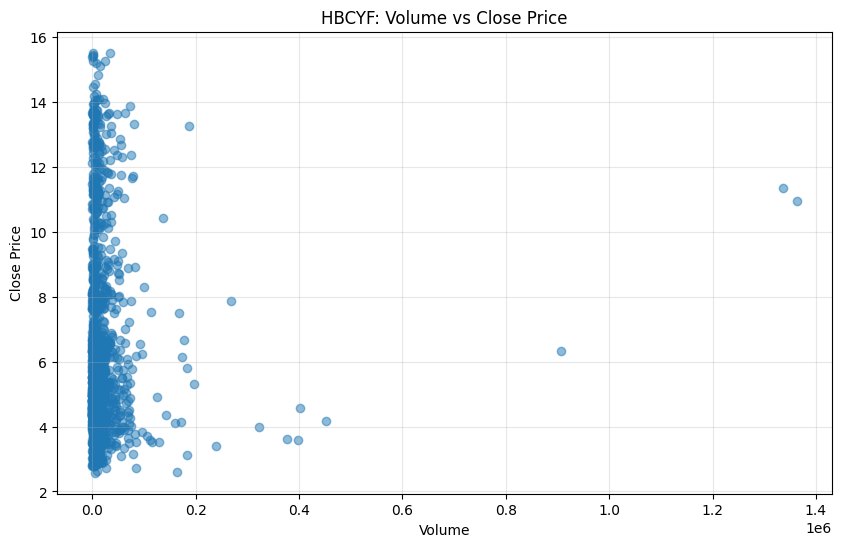

HBCYF Regression Summary:
                            OLS Regression Results                            
Dep. Variable:                  Close   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.266
Date:                Sun, 18 Oct 2026   Prob (F-statistic):              0.261
Time:                        11:57:56   Log-Likelihood:                -3719.6
No. Observations:                1508   AIC:                             7443.
Df Residuals:                    1506   BIC:                             7454.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.3746     

In [49]:
# Regression Analysis: HBCYF (HSBC)
ticker_data = data_volume['HBCYF'].dropna()
X = ticker_data[['Volume']] 
Y = ticker_data['Close']

plt.figure(figsize=(10, 6))
plt.scatter(X, Y, alpha=0.5)
plt.xlabel('Volume')
plt.ylabel('Close Price')
plt.title('HBCYF: Volume vs Close Price')
plt.grid(True, alpha=0.3)
plt.show()

# Regression summary
X1 = sm.add_constant(X)
reg = sm.OLS(Y, X1).fit()
print("HBCYF Regression Summary:")
print(reg.summary())

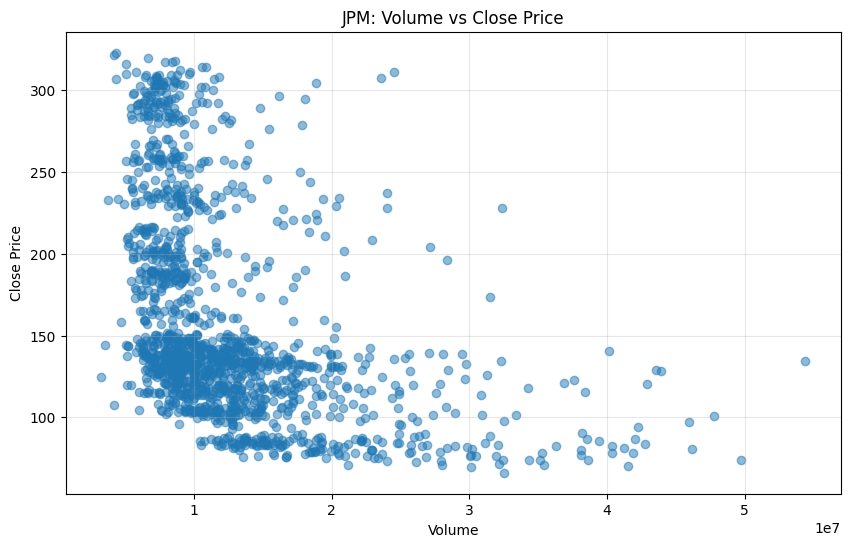

JPM Regression Summary:
                            OLS Regression Results                            
Dep. Variable:                  Close   R-squared:                       0.185
Model:                            OLS   Adj. R-squared:                  0.184
Method:                 Least Squares   F-statistic:                     341.0
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           8.56e-69
Time:                        11:57:57   Log-Likelihood:                -8231.0
No. Observations:                1508   AIC:                         1.647e+04
Df Residuals:                    1506   BIC:                         1.648e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        206.8341      3

In [50]:
# Regression Analysis: JPM (JPMorgan Chase)
ticker_data = data_volume['JPM'].dropna()
X = ticker_data[['Volume']] 
Y = ticker_data['Close']

plt.figure(figsize=(10, 6))
plt.scatter(X, Y, alpha=0.5)
plt.xlabel('Volume')
plt.ylabel('Close Price')
plt.title('JPM: Volume vs Close Price')
plt.grid(True, alpha=0.3)
plt.show()

# Regression summary
X1 = sm.add_constant(X)
reg = sm.OLS(Y, X1).fit()
print("JPM Regression Summary:")
print(reg.summary())

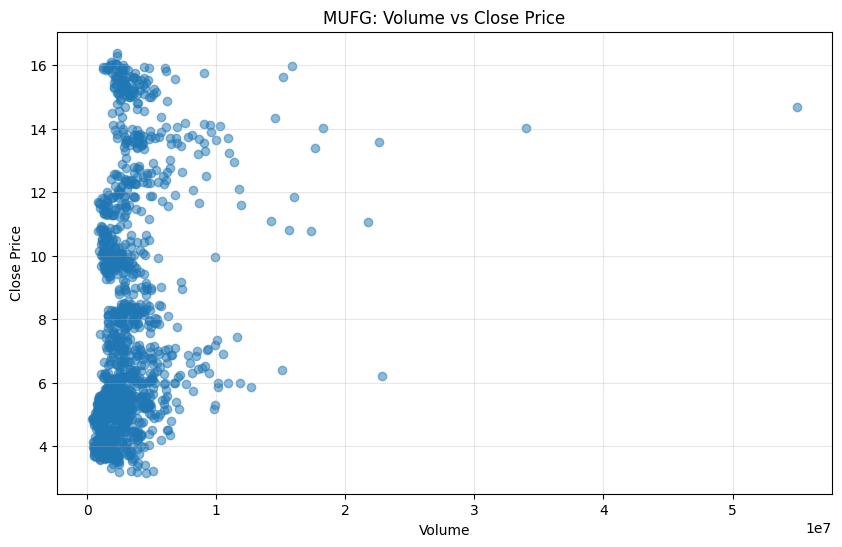

MUFG Regression Summary:
                            OLS Regression Results                            
Dep. Variable:                  Close   R-squared:                       0.078
Model:                            OLS   Adj. R-squared:                  0.078
Method:                 Least Squares   F-statistic:                     127.6
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           1.82e-28
Time:                        11:57:57   Log-Likelihood:                -3978.7
No. Observations:                1508   AIC:                             7961.
Df Residuals:                    1506   BIC:                             7972.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.5642      

In [51]:
# Regression Analysis: MUFG (Mitsubishi UFJ)
ticker_data = data_volume['MUFG'].dropna()
X = ticker_data[['Volume']] 
Y = ticker_data['Close']

plt.figure(figsize=(10, 6))
plt.scatter(X, Y, alpha=0.5)
plt.xlabel('Volume')
plt.ylabel('Close Price')
plt.title('MUFG: Volume vs Close Price')
plt.grid(True, alpha=0.3)
plt.show()

# Regression summary
X1 = sm.add_constant(X)
reg = sm.OLS(Y, X1).fit()
print("MUFG Regression Summary:")
print(reg.summary())

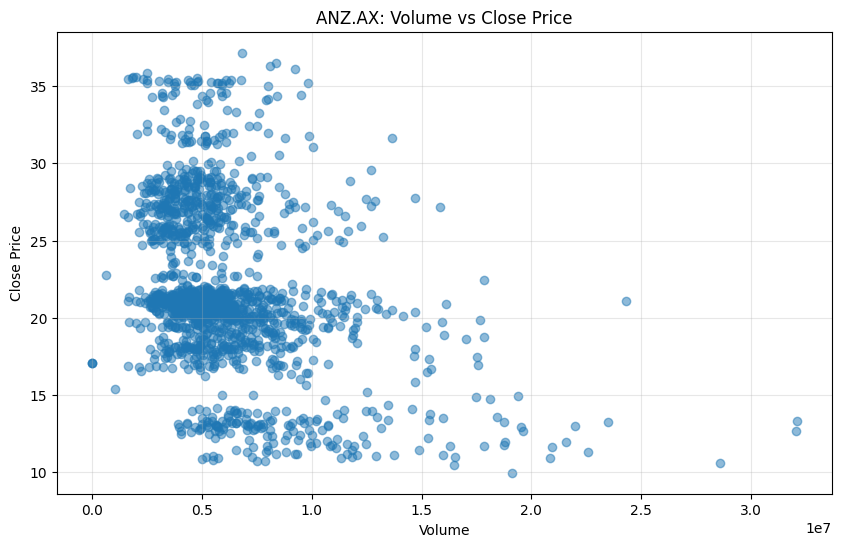

ANZ.AX Regression Summary:
                            OLS Regression Results                            
Dep. Variable:                  Close   R-squared:                       0.131
Model:                            OLS   Adj. R-squared:                  0.130
Method:                 Least Squares   F-statistic:                     227.8
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           4.53e-48
Time:                        11:57:57   Log-Likelihood:                -4624.6
No. Observations:                1519   AIC:                             9253.
Df Residuals:                    1517   BIC:                             9264.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         25.5293    

In [52]:
# Regression Analysis: ANZ.AX (ANZ Bank)
ticker_data = data_volume['ANZ.AX'].dropna()
X = ticker_data[['Volume']] 
Y = ticker_data['Close']

plt.figure(figsize=(10, 6))
plt.scatter(X, Y, alpha=0.5)
plt.xlabel('Volume')
plt.ylabel('Close Price')
plt.title('ANZ.AX: Volume vs Close Price')
plt.grid(True, alpha=0.3)
plt.show()

# Regression summary
X1 = sm.add_constant(X)
reg = sm.OLS(Y, X1).fit()
print("ANZ.AX Regression Summary:")
print(reg.summary())

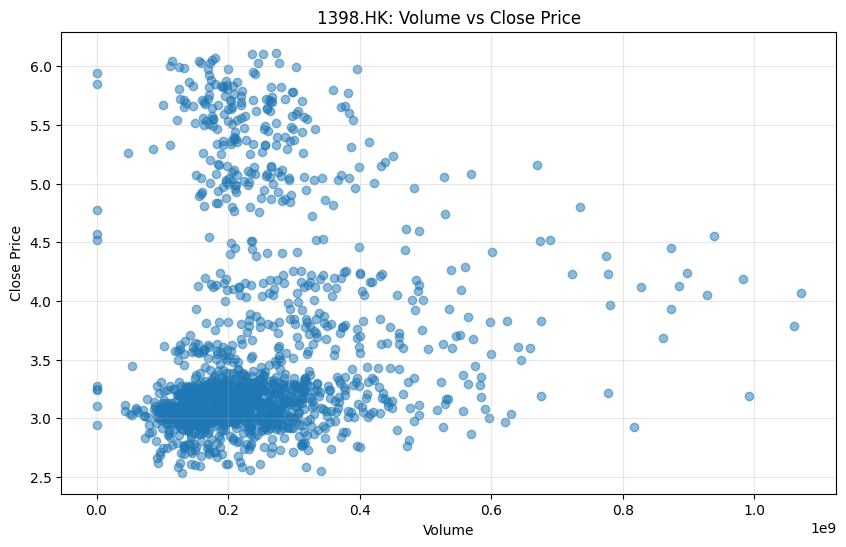

1398.HK Regression Summary:
                            OLS Regression Results                            
Dep. Variable:                  Close   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                  0.016
Method:                 Least Squares   F-statistic:                     24.60
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           7.85e-07
Time:                        11:57:57   Log-Likelihood:                -1871.4
No. Observations:                1476   AIC:                             3747.
Df Residuals:                    1474   BIC:                             3757.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.3626   

In [53]:
# Regression Analysis: 1398.HK (HSBC Hong Kong)
ticker_data = data_volume['1398.HK'].dropna()
X = ticker_data[['Volume']] 
Y = ticker_data['Close']

plt.figure(figsize=(10, 6))
plt.scatter(X, Y, alpha=0.5)
plt.xlabel('Volume')
plt.ylabel('Close Price')
plt.title('1398.HK: Volume vs Close Price')
plt.grid(True, alpha=0.3)
plt.show()

# Regression summary
X1 = sm.add_constant(X)
reg = sm.OLS(Y, X1).fit()
print("1398.HK Regression Summary:")
print(reg.summary())

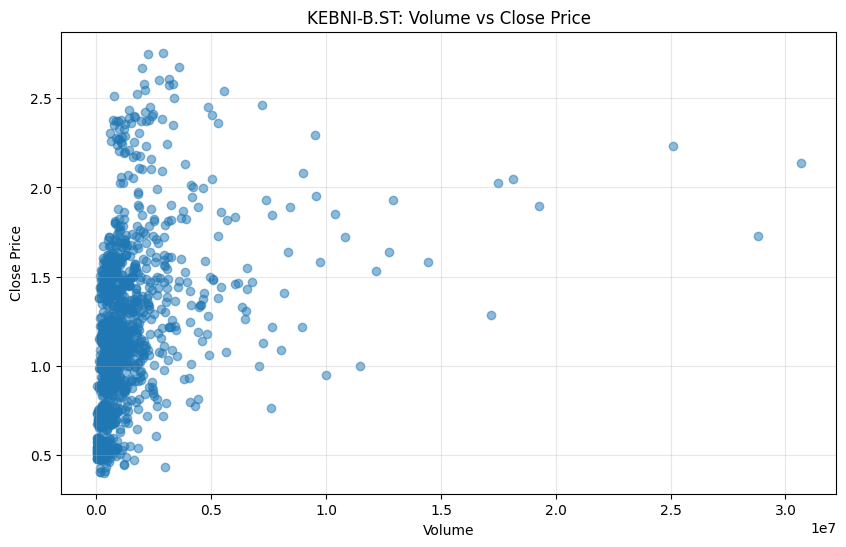

KEBNI-B.ST Regression Summary:
                            OLS Regression Results                            
Dep. Variable:                  Close   R-squared:                       0.125
Model:                            OLS   Adj. R-squared:                  0.124
Method:                 Least Squares   F-statistic:                     192.0
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           6.59e-41
Time:                        11:57:58   Log-Likelihood:                -773.05
No. Observations:                1347   AIC:                             1550.
Df Residuals:                    1345   BIC:                             1561.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.0677

In [54]:
# Regression Analysis: KEBNI-B.ST (Kookmin Bank)
ticker_data = data_volume['KEBNI-B.ST'].dropna()
X = ticker_data[['Volume']] 
Y = ticker_data['Close']

plt.figure(figsize=(10, 6))
plt.scatter(X, Y, alpha=0.5)
plt.xlabel('Volume')
plt.ylabel('Close Price')
plt.title('KEBNI-B.ST: Volume vs Close Price')
plt.grid(True, alpha=0.3)
plt.show()

# Regression summary
X1 = sm.add_constant(X)
reg = sm.OLS(Y, X1).fit()
print("KEBNI-B.ST Regression Summary:")
print(reg.summary())